# 16 · Attention, RoPE and the KV cache in the streaming decoder

The fUSI transformer (`workloads/fusi_realtime/models.py`, `FusiDecoder`) is trained on windows of
frames but deployed one volume at a time. This notebook builds the pieces from scratch and
verifies the property the deployment depends on:

> decoding one volume per step with a per-layer KV cache gives the **same logits** as a full
> forward pass over the whole sequence, for arbitrarily long streams, with memory bounded by the
> attention window.

Contents: (1) scaled dot-product attention written out and checked against
`torch.nn.functional.scaled_dot_product_attention` for prefill and single-token decode;
(2) rotary position embeddings (RoPE) and why relative positions make sliding-window streaming
exact; (3) `FusiDecoder.step` vs `forward`; (4) dropped frames; (5) cost of cached vs recomputed
steps; (6) memory.

## Conceptual model

**Architecture.** Per volume: cubic patches → linear embedding → one bidirectional attention
block over the patches of *that volume* → flatten + linear → **one token per volume**. Over time:
$L$ causal blocks with RoPE and a sliding window of $W$ frames → LayerNorm → head with 8 logits
per frame.

**Attention.** For queries $Q$ and keys/values $K, V$ of head width $d$:

$$\operatorname{Attn}(Q,K,V) = \operatorname{softmax}\!\Big(\tfrac{QK^\top}{\sqrt d} + M\Big)V,\qquad M_{ij} = \begin{cases}0 & \text{visible}\\ -\infty & \text{masked}\end{cases}$$

The band-causal mask here lets frame $i$ see frames $j$ with $0 \le i-j < W$.

**RoPE.** Rotate each consecutive pair of query/key features by an angle proportional to the
absolute position, $\theta_k\,p$. For a rotation $R_p$, $\langle R_p q, R_{p'} k\rangle = \langle q, R_{p'-p} k\rangle$,
so the score depends only on the **relative** offset. Absolute position never enters the
computation except through differences.

**KV cache.** In a causal model, keys and values of past tokens never change when new tokens
arrive. Cache them per layer, compute only the new token's $q, k, v$, and attend over the cache.
With a window, evict entries older than $W-1$ frames; they are masked for every future query
anyway. Because RoPE is relative, cached keys stay valid after eviction: nothing needs
re-indexing.

In [1]:
import os, sys, tempfile, time, warnings
from pathlib import Path

os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
os.environ.setdefault("ML_LOG_LEVEL", "WARNING")   # keep structlog output out of the notebook
os.environ.setdefault("RAY_DEDUP_LOGS", "1")
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)
pd.set_option("display.width", 120)
plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (7.5, 3.6), "axes.grid": True,
                     "grid.alpha": 0.3})

# Every artifact this notebook creates lives in a fresh temp dir -- never in the repo's
# data/, artifacts/ or mlflow.db.
WORK = Path(tempfile.mkdtemp(prefix="nb16_"))
T0 = time.perf_counter()
print("workspace:", WORK)

workspace: /var/folders/vx/0jy3t_qx56q4d0qpnmgs008r0000gn/T/nb16__g3fibhc


In [2]:
import math
import torch
import torch.nn.functional as F

from ml_platform.workloads.fusi_realtime import models as M
from ml_platform.workloads.fusi_realtime.config import DecoderConfig

torch.manual_seed(0)
torch.set_num_threads(2)                          # the real-time config uses 2 torch threads
print("torch", torch.__version__, "| threads", torch.get_num_threads())

torch 2.14.0 | threads 2


## 1 · Scaled dot-product attention from scratch

Three steps, spelled out: scores $QK^\top/\sqrt d$, masking (`-inf` before the softmax so masked
keys get weight exactly 0), softmax over keys, weighted sum of values. The version in
`models.attention` is the same arithmetic; here it is written again and compared with PyTorch's
fused kernel.

In [3]:
def sdpa(q, k, v, mask=None):
    # q: (..., Tq, d)   k, v: (..., Tk, d)   mask: bool broadcastable to (..., Tq, Tk), True = visible
    d = q.shape[-1]
    scores = q @ k.transpose(-2, -1) / math.sqrt(d)                # (..., Tq, Tk)
    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))
    weights = torch.softmax(scores, dim=-1)                          # each row sums to 1 over visible keys
    return weights @ v

B, H, T, d = 2, 4, 24, 16
q, k, v = (torch.randn(B, H, T, d) for _ in range(3))
pos = torch.arange(T)

# (a) prefill: causal, and band-causal with window 6
causal = M.band_causal_mask(pos, pos, window=T)                      # j <= i
band = M.band_causal_mask(pos, pos, window=6)                        # i - 6 < j <= i
ref_c = F.scaled_dot_product_attention(q, k, v, is_causal=True)
ref_b = F.scaled_dot_product_attention(q, k, v, attn_mask=band)
err_c = (sdpa(q, k, v, causal) - ref_c).abs().max().item()
err_b = (sdpa(q, k, v, band) - ref_b).abs().max().item()
err_lib = (M.attention(q, k, v, band) - ref_b).abs().max().item()
print(f"prefill causal      max |scratch - SDPA| = {err_c:.2e}")
print(f"prefill band (W=6)  max |scratch - SDPA| = {err_b:.2e}    |models.attention - SDPA| = {err_lib:.2e}")
assert max(err_c, err_b, err_lib) < 1e-5

# (b) decode: the last token's query against a cache of all keys/values, no mask needed
out_full = F.scaled_dot_product_attention(q, k, v, is_causal=True)[:, :, -1:]       # last row of prefill
out_dec = sdpa(q[:, :, -1:], k, v)                                                     # cache = k, v of tokens 0..T-1
out_dec_sdpa = F.scaled_dot_product_attention(q[:, :, -1:], k, v)
print(f"decode vs last prefill row: {(out_dec - out_full).abs().max():.2e};  vs SDPA decode: {(out_dec - out_dec_sdpa).abs().max():.2e}")
assert (out_dec - out_full).abs().max() < 1e-5

# (c) windowed decode: evicting keys outside the window changes nothing, because they were masked
W = 6
out_win_full = F.scaled_dot_product_attention(q, k, v, attn_mask=band)[:, :, -1:]
out_win_cache = sdpa(q[:, :, -1:], k[:, :, -W:], v[:, :, -W:])
print(f"windowed decode against a cache of only the last {W} keys: {(out_win_cache - out_win_full).abs().max():.2e}")

prefill causal      max |scratch - SDPA| = 4.77e-07
prefill band (W=6)  max |scratch - SDPA| = 3.58e-07    |models.attention - SDPA| = 3.58e-07
decode vs last prefill row: 1.79e-07;  vs SDPA decode: 2.38e-07
windowed decode against a cache of only the last 6 keys: 2.38e-07


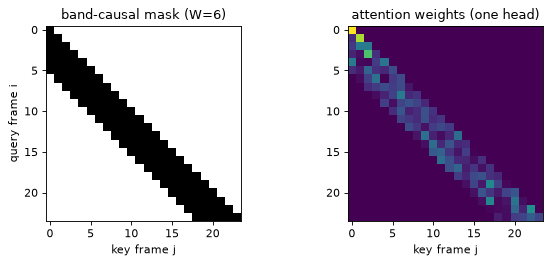

In [4]:
w = torch.softmax(q[0, 0] @ k[0, 0].T / math.sqrt(d) + torch.where(band, 0.0, float("-inf"))[:, :], dim=-1)
fig, ax = plt.subplots(1, 2, figsize=(8, 3.4))
ax[0].imshow(band, cmap="gray_r"); ax[0].set(title="band-causal mask (W=6)", xlabel="key frame j", ylabel="query frame i")
ax[1].imshow(w, cmap="viridis"); ax[1].set(title="attention weights (one head)", xlabel="key frame j")
for a in ax: a.grid(False)
plt.tight_layout(); plt.show()

## 2 · RoPE: scores depend on relative position only

`rope(x, pos)` rotates feature pairs $(x_{2k}, x_{2k+1})$ by $\mathrm{pos}\cdot\theta_k$ with
$\theta_k = 10000^{-2k/d}$. Take one query vector and one key vector and score them at many
absolute positions with a fixed offset; then change the offset.

                p=0      p=3     p=17    p=100   p=1000   spread
offset i-j                                                      
0          -1.71085 -1.71085 -1.71085 -1.71085 -1.71085 +0.00000
1          -0.34269 -0.34269 -0.34269 -0.34269 -0.34264 +0.00005
5          -0.31542 -0.31542 -0.31542 -0.31542 -0.31542 +0.00000
20         +1.90915 +1.90915 +1.90915 +1.90915 +1.90915 +0.00000
rotation preserves norms: True
unrotated score <q, k> = -1.71085 (equals the offset-0 score)


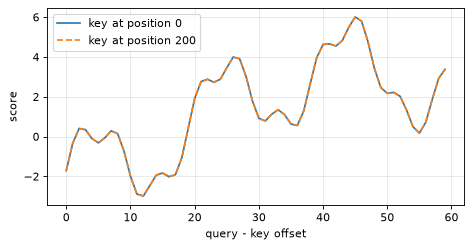

In [5]:
qv, kv = torch.randn(1, 1, 1, 16), torch.randn(1, 1, 1, 16)
def score(p_q, p_k):
    return (M.rope(qv, torch.tensor([p_q])) * M.rope(kv, torch.tensor([p_k]))).sum().item()

rows = []
for off in (0, 1, 5, 20):
    s = [score(p + off, p) for p in (0, 3, 17, 100, 1000)]
    rows.append({"offset i-j": off, **{f"p={p}": x for p, x in zip((0, 3, 17, 100, 1000), s)}, "spread": max(s) - min(s)})
print(pd.DataFrame(rows).set_index("offset i-j").to_string(float_format=lambda x: f"{x:+.5f}"))
print("rotation preserves norms:", torch.allclose(M.rope(qv, torch.tensor([37])).norm(), qv.norm(), atol=1e-5))
print("unrotated score <q, k> =", f"{(qv * kv).sum().item():+.5f}", "(equals the offset-0 score)")

offs = np.arange(0, 60)
fig, ax = plt.subplots(figsize=(6, 3.2))
for p in (0, 200):
    ax.plot(offs, [score(p + o, p) for o in offs], label=f"key at position {p}", ls="-" if p == 0 else "--")
ax.set(xlabel="query - key offset", ylabel="score"); ax.legend(); plt.tight_layout(); plt.show()

In exact arithmetic the score is a function of $i-j$ only, which is why evicting old cache
entries needs no position bookkeeping and the cached keys stay valid as the stream advances.
(Absolute positions are still *passed in*, see section 4, but only differences matter.) In
float32 the invariance holds to round-off, and the spread grows with the absolute position
(already ~5e-5 at p = 1000 for offset 1, because `pos * theta` loses mantissa bits); streams of
hours at 10 Hz would need float64 angles or a periodic position reset.

## 3 · `FusiDecoder`: full forward vs cached steps

Default decoder configuration, 16³ volumes (8 patches of 8³ per volume), a window of 24 frames,
a stream of 70 frames so that eviction is exercised. `forward` sees the whole sequence with the
band mask; `step` sees one volume at a time and keeps a `LayerCache` per layer.

In [6]:
GRID = (16, 16, 16)
dcfg = DecoderConfig()                                  # patch 8, d_model 32, 4 heads, 2 layers, window 24
model = M.build_decoder(dcfg, GRID, n_classes=8).eval()
n_par = sum(p.numel() for p in model.parameters())
print(f"FusiDecoder: {n_par:,} parameters; {model.spatial.n_patches} patches/volume; window {dcfg.attn_window}; "
      f"layers {dcfg.n_layers}; dropout {dcfg.dropout} (inactive in eval())")

T = 70
x = torch.randn(1, T, *GRID)
with torch.inference_mode():
    full = model(x)                                      # (1, T, 8), positions default to 0..T-1
    cache, stream, cache_len = None, [], []
    for t in range(T):
        logits, cache = model.step(x[:, t], t, cache)
        stream.append(logits)
        cache_len.append([len(c.pos) for c in cache])
stream = torch.stack(stream, dim=1)

diff = (stream - full).abs()
print(f"max |step - forward| over {T} frames x 8 logits = {diff.max():.2e}  (assert < 1e-5)")
assert diff.max() < 1e-5
print("argmax agreement:", bool((stream.argmax(-1) == full.argmax(-1)).all()))
print(f"cache entries per layer: after frame 1: {cache_len[0]}, frame 24: {cache_len[23]}, frame 25: {cache_len[24]}, "
      f"frame {T}: {cache_len[-1]}   (bounded by the window)")

FusiDecoder: 54,920 parameters; 8 patches/volume; window 24; layers 2; dropout 0.3 (inactive in eval())
max |step - forward| over 70 frames x 8 logits = 6.56e-07  (assert < 1e-5)
argmax agreement: True
cache entries per layer: after frame 1: [1, 1], frame 24: [24, 24], frame 25: [24, 24], frame 70: [24, 24]   (bounded by the window)


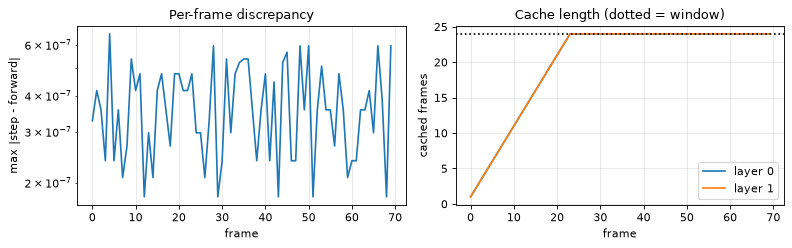

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].semilogy(diff.amax(dim=(0, 2)) + 1e-12); ax[0].set(xlabel="frame", ylabel="max |step - forward|", title="Per-frame discrepancy")
ax[1].plot(cache_len, label=["layer 0", "layer 1"]); ax[1].axhline(dcfg.attn_window, c="k", ls=":")
ax[1].set(xlabel="frame", ylabel="cached frames", title="Cache length (dotted = window)"); ax[1].legend()
plt.tight_layout(); plt.show()

**Receptive field.** One layer sees $W$ frames, but layer-2 queries read layer-1 outputs that
themselves summarise earlier frames, so the model's effective receptive field is
$L(W-1)+1$ frames (47 here). The cache is still exact: the layer-$l$ cache stores keys/values
computed from *that layer's inputs*, which already contain everything below. This is
the difference between caching **K/V per layer** (exact) and keeping only the last $W$ *input
frames* and re-running the model on them (a cheaper-looking but different function).

## 4 · Dropped frames and absolute positions

The real-time path drops a frame rather than queueing it when the pipeline is late. The decoder
is then called with a gap in frame indices. Because the cache stores **absolute** positions and
the window mask is computed from position differences, a gap is a gap: a frame 24 steps before
the current one has left the window whether or not the intermediate frames arrived.

Here frames 30-33 are dropped. The reference is `forward` on the surviving frames *with their
true positions*; the alternative is the mistake of renumbering them 0..n-1.

In [8]:
keep = [t for t in range(T) if not 30 <= t < 34]
pos_keep = torch.tensor(keep)
with torch.inference_mode():
    ref_gap = model(x[:, keep], pos_keep)                 # full forward, absolute positions
    ref_renum = model(x[:, keep])                          # WRONG: positions renumbered, the gap disappears
    cache, out = None, []
    for t in keep:                                         # streaming: just skip the dropped frames
        lg, cache = model.step(x[:, t], t, cache)
        out.append(lg)
out = torch.stack(out, dim=1)
print(f"stream with a gap vs forward(abs positions): {(out - ref_gap).abs().max():.2e}")
print(f"stream with a gap vs forward(renumbered):    {(out - ref_renum).abs().max():.2e}   <- positions must not be renumbered")
assert (out - ref_gap).abs().max() < 1e-5
print("frames whose logits differ between absolute and renumbered positions (> 1e-4):",
      int(((out - ref_renum).abs().amax(dim=(0, 2)) > 1e-4).sum()), "of", len(keep))

stream with a gap vs forward(abs positions): 6.56e-07
stream with a gap vs forward(renumbered):    2.04e-01   <- positions must not be renumbered
frames whose logits differ between absolute and renumbered positions (> 1e-4): 36 of 66


Frames that fall inside the window across the gap are affected by renumbering because they get
wrong relative offsets, and frames that should have left the window stay in it. In
`realtime.py` the source's frame index (not a count of processed frames) is passed to
`StreamingDecoder.step`, which is what keeps the two equal.

## 5 · Cost per step: recompute vs cache

Without a cache, producing the logits of the newest frame means re-running the model over the
last $W$ volumes, including the spatial encoder for every one of them. With the cache, only the
new volume is encoded and attended from. Median of 30 timings on this machine's CPU, 2 threads,
16³ volumes.

          full recompute (ms)  cached step (ms)  speedup
window W                                                
4                        0.29              0.24     1.22
8                        0.32              0.24     1.35
16                       0.39              0.24     1.64
24                       0.45              0.24     1.86
48                       0.63              0.24     2.62


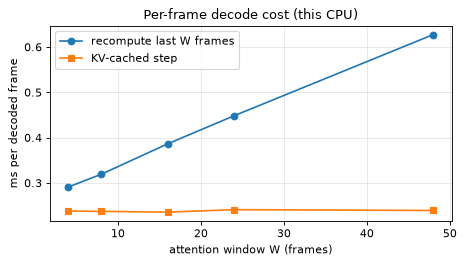

32^3, W=24: full recompute 1.2 ms, cached step 0.3 ms, speedup 4.1x


In [9]:
def bench(fn, n=30):
    for _ in range(3): fn()
    ts = []
    for _ in range(n):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return float(np.median(ts)) * 1e3

rows = []
for W in (4, 8, 16, 24, 48):
    m = M.build_decoder(DecoderConfig(attn_window=W), GRID, 8).eval()
    xs = torch.randn(1, W + 8, *GRID)
    with torch.inference_mode():
        cache = None
        for t in range(W + 4):                                 # warm the cache to its steady-state length
            _, cache = m.step(xs[:, t], t, cache)
        state = {"c": cache, "t": W + 4}
        def cached():
            _, state["c"] = m.step(xs[:, W + 4], state["t"], state["c"])
            state["t"] += 1
        t_cached = bench(cached)
        win = xs[:, :W]
        t_full = bench(lambda: m(win)[:, -1])
    rows.append({"window W": W, "full recompute (ms)": t_full, "cached step (ms)": t_cached, "speedup": t_full / t_cached})
cost = pd.DataFrame(rows).set_index("window W")
print(cost.to_string(float_format=lambda x: f"{x:.2f}"))
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(cost.index, cost["full recompute (ms)"], "o-", label="recompute last W frames")
ax.plot(cost.index, cost["cached step (ms)"], "s-", label="KV-cached step")
ax.set(xlabel="attention window W (frames)", ylabel="ms per decoded frame", title="Per-frame decode cost (this CPU)"); ax.legend()
plt.tight_layout(); plt.show()

# same comparison at the real-time grid (32^3 -> 64 patches), window 24
g32 = (32, 32, 32); m32 = M.build_decoder(DecoderConfig(attn_window=24), g32, 8).eval(); xs = torch.randn(1, 32, *g32)
with torch.inference_mode():
    c = None
    for t in range(28): _, c = m32.step(xs[:, t], t, c)
    st = {"c": c, "t": 28}
    def cached32():
        _, st["c"] = m32.step(xs[:, 28], st["t"], st["c"]); st["t"] += 1
    tc = bench(cached32, n=15); tf = bench(lambda: m32(xs[:, :24])[:, -1], n=15)
print(f"32^3, W=24: full recompute {tf:.1f} ms, cached step {tc:.1f} ms, speedup {tf / tc:.1f}x")

Reading the plot:

* Recompute grows with $W$, because the spatial encoder (patch embedding + patch attention +
  flatten/linear) is run $W$ times. The cached step encodes one volume and attends one query
  over at most $W$ cached keys, $O(W\,d)$ per layer.
* The cached step is nearly flat in $W$. At this model size (55 k parameters, 8 patches) it is
  dominated by fixed per-call overhead, so the speedup is modest and grows with $W$; at 32³
  volumes and larger models the spatial encoder dominates and the gap widens.
* This is wall-clock on one machine with one batch element; the ratio, not the absolute
  milliseconds, is the transferable part.

## 6 · Memory is $O(W)$

Per layer the cache holds keys and values of shape $(B, H, \le W, d_h)$ in float32 plus the
positions. Independent of how long the stream runs:

In [10]:
def cache_bytes(cache):
    return sum(c.k.numel() * c.k.element_size() + c.v.numel() * c.v.element_size() + c.pos.numel() * c.pos.element_size()
               for c in cache)

with torch.inference_mode():
    cache, sizes = None, []
    xs = torch.randn(1, 4, *GRID)
    for t in range(600):                                   # 60 s of stream at 10 Hz, reusing 4 random volumes
        _, cache = model.step(xs[:, t % 4], t, cache)
        if t in (10, 23, 24, 100, 599):
            sizes.append({"frame": t, "cached frames/layer": len(cache[0].pos), "cache KiB (all layers)": cache_bytes(cache) / 1024})
print(pd.DataFrame(sizes).set_index("frame").to_string(float_format=lambda x: f"{x:.1f}"))
dh = dcfg.d_model // dcfg.n_heads
print(f"analytic: 2 (K,V) x {dcfg.n_layers} layers x {dcfg.n_heads} heads x {dcfg.attn_window} x {dh} x 4 B = "
      f"{2 * dcfg.n_layers * dcfg.n_heads * dcfg.attn_window * dh * 4 / 1024:.1f} KiB (+ int64 positions)")

       cached frames/layer  cache KiB (all layers)
frame                                             
10                      11                     5.7
23                      24                    12.4
24                      24                    12.4
100                     24                    12.4
599                     24                    12.4
analytic: 2 (K,V) x 2 layers x 4 heads x 24 x 8 x 4 B = 12.0 KiB (+ int64 positions)


A few tens of KiB per stream: the cache is irrelevant next to the volume (16³ float32 = 16 KiB,
32³ = 128 KiB) and the model weights. Memory would only matter for large $d_{model}$, long
windows or many concurrent streams.

## Connection to this repository

* `models.py`: `attention`, `band_causal_mask`, `rope`, `CausalSelfAttention.forward/step`,
  `FusiDecoder.forward/step`, `StreamingDecoder` (the hot-path wrapper, softmax on the logits).
* `tests/unit/test_fusi_models.py` asserts the same equalities as this notebook.
* `realtime.py`: `DecoderActor` owns one `StreamingDecoder` and passes the source frame index as
  the position; the decoder weights can be hot-swapped without touching the frame stream.
* Training uses `forward` over windows of `window_frames` (24) with the same mask, so the
  train-time and serve-time functions are identical.

## Pitfalls

* **Train/serve skew in positions.** Renumbering after a drop, or resetting positions at every
  window, changes the function.
* **Cache after a weight swap.** A cache built with old weights is invalid for new weights; a
  swap must reset it (or accept a window of transient output).
* **Dropout** must be off (`eval()`); in train mode `step` and `forward` differ by design.
* **Eviction at the wrong boundary.** The window is `0 <= q - k < W`, i.e. the new token plus
  $W-1$ cached ones; an off-by-one here still "works" but no longer equals `forward`.
* **Float agreement is ~1e-7, not 0.** Different reduction orders (fused SDPA vs explicit
  softmax, batched vs single-row matmuls) differ at round-off; compare with tolerances, and
  compare decisions (argmax) rather than raw probabilities when thresholds matter.
* **Batch size.** The benchmark uses one stream; with many streams the cost model changes
  (the matmuls batch well, the Python overhead of `step` does not).

## Exercise

1. Change the mask to `i - j <= W` (off by one) in a copy of `band_causal_mask` and find the
   smallest stream length at which `step` and `forward` first disagree.
2. Remove RoPE (use identical positions for all frames) and add a learned absolute position
   embedding instead. What breaks when the stream is longer than the training windows?
3. Cache the *spatial tokens* instead of per-layer K/V and recompute the temporal blocks over
   the window each step. Is it exact? What does it cost relative to section 5?

In [11]:
import shutil
shutil.rmtree(WORK, ignore_errors=True)
print(f"done in {time.perf_counter() - T0:.1f}s; workspace removed")

done in 1.2s; workspace removed
